In [31]:
import pandas as pd
import glob
import joblib

# combine all chunks
files = sorted(glob.glob('/content/chunk_*.csv'))
df = pd.concat([pd.read_csv(f) for f in files])
print(df.shape)

(81100, 136)


In [32]:
print(df['stay_id'].is_unique)
print(df['duration_days'].max())
print(df['event'].sum())
print(df['event'].isin([0, 1]).all())

True
30.0
7281
True


In [33]:
!pip install lifelines
from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import multivariate_logrank_test

kmf=KaplanMeierFitter()
kmf.fit(durations=df['duration_days'], event_observed=df['event'], label='Kaplan Meier Estimate')
kmf.survival_function_at_times([7, 14, 30])

,Kaplan Meier Estimate
7,0.922344
14,0.846798
30,0.717848


In [ ]:
import numpy as np

conditions = [
    df['event'] == 1,
    (df['event'] == 0) & (df['duration_days'] < 30)
]

choices = [1, 2]

df['event_of_interest'] = np.select(conditions, choices, default=0)
df.head()

sofa_group
0-2    29026
5-8    23051
3-4    20140
9+      8883
Name: count, dtype: int64


<lifelines.StatisticalResult: multivariate_logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 3
         test_name = multivariate_logrank_test

---
 test_statistic      p  -log2(p)
        2810.01 <0.005       inf

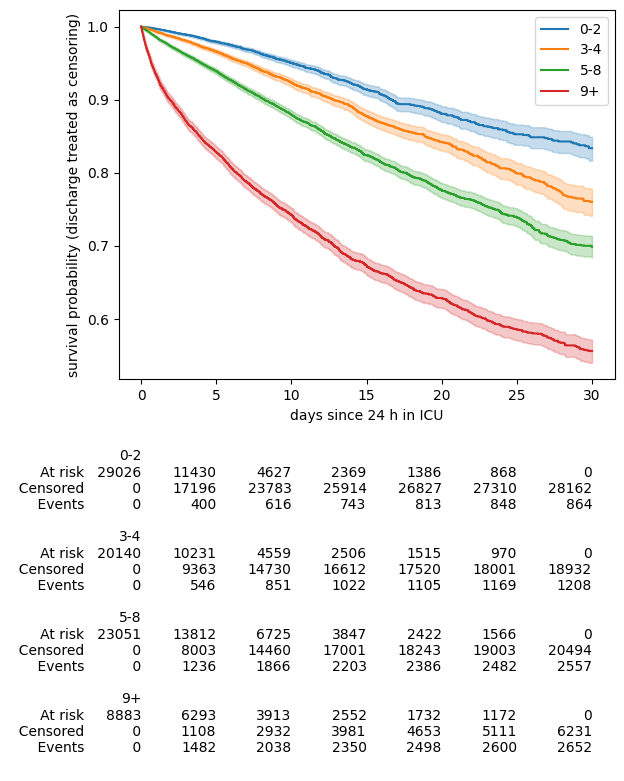

In [35]:
import matplotlib.pyplot as plt
strat = df.dropna(subset=['sofa']).copy()
strat['sofa_group'] = pd.cut(strat['sofa'], bins=[0, 2, 4, 8, np.inf], labels=['0-2', '3-4', '5-8', '9+'], include_lowest=True)
print(strat['sofa_group'].value_counts())

fig, ax = plt.subplots()
fitters = []
for name, g in strat.groupby('sofa_group', observed=True):
    k = KaplanMeierFitter()
    k.fit(g['duration_days'], g['event'], label=str(name))
    k.plot_survival_function(ax=ax, xlabel='days since 24 h in ICU', ylabel='survival probability (discharge treated as censoring)')
    fitters.append(k)
add_at_risk_counts(*fitters, ax=ax)
plt.savefig("km_sofa.png", dpi=300, bbox_inches="tight")

multivariate_logrank_test(strat['duration_days'], strat['sofa_group'], strat['event'])

In [36]:
df_encoded = pd.get_dummies(df, columns=['first_careunit', 'admission_type'])

cov = ['age', 'gcs_motor', 'urineoutput', 'resp_rate_mean', 'bun_max', 'spo2_min',
       'wbc_min', 'hemoglobin_max', 'heart_rate_mean', 'sbp_mean', 'temperature_min',
       'ventilated_day1', 'first_careunit_Cardiac Vascular Intensive Care Unit (CVICU)',
       'admission_type_SURGICAL SAME DAY ADMISSION']

model_df = df_encoded[['subject_id', 'duration_days', 'event'] + cov].copy()
model_df.isna().sum()

,0
subject_id,0
duration_days,0
event,0
age,0
gcs_motor,719
urineoutput,3396
resp_rate_mean,196
bun_max,563
spo2_min,118
wbc_min,664


In [37]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

In [38]:
bin_cols = ['ventilated_day1',
            'first_careunit_Cardiac Vascular Intensive Care Unit (CVICU)',
            'admission_type_SURGICAL SAME DAY ADMISSION']
cont_cols = [c for c in cov if c not in bin_cols]

model_df.loc[model_df['urineoutput'] < 0, 'urineoutput'] = np.nan
for c in ['urineoutput', 'bun_max', 'wbc_min']:
    model_df[c] = np.log1p(model_df[c])

train_idx, test_idx = next(GroupShuffleSplit(test_size=.20, n_splits=1, random_state=42)
                           .split(model_df, groups=model_df['subject_id']))
train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()
lo = train_df[cont_cols].quantile(0.005)
hi = train_df[cont_cols].quantile(0.995)
train_df[cont_cols] = train_df[cont_cols].clip(lo, hi, axis=1)
test_df[cont_cols] = test_df[cont_cols].clip(lo, hi, axis=1)

imp = SimpleImputer(strategy='median')
scaler = StandardScaler()
train_df[cont_cols] = scaler.fit_transform(imp.fit_transform(train_df[cont_cols]))
test_df[cont_cols] = scaler.transform(imp.transform(test_df[cont_cols]))

In [39]:
train_df[cont_cols].describe()

,age,gcs_motor,urineoutput,resp_rate_mean,bun_max,spo2_min,wbc_min,hemoglobin_max,heart_rate_mean,sbp_mean,temperature_min
count,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04,6.469900e+04
mean,1.976811e-16,-2.323851e-16,1.394860e-15,-3.102495e-16,2.102009e-16,-1.088344e-16,-3.255149e-16,-4.131535e-16,4.118356e-16,3.098102e-16,3.473916e-15
std,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00,1.000008e+00
min,-2.675360e+00,-2.878171e+00,-5.532188e+00,-1.914687e+00,-2.151965e+00,-5.780956e+00,-3.804090e+00,-2.031338e+00,-2.230833e+00,-1.997761e+00,-5.153151e+00
25%,-5.847291e-01,4.569794e-01,-3.885628e-01,-7.096687e-01,-6.925312e-01,-3.766028e-01,-5.821504e-01,-7.285530e-01,-7.130983e-01,-7.323717e-01,-2.843441e-01
50%,7.232613e-02,4.569794e-01,1.454659e-01,-1.603221e-01,-1.566109e-01,2.238808e-01,2.971346e-02,-3.063246e-02,-9.642708e-02,-1.472429e-01,1.705271e-01
75%,7.293814e-01,4.569794e-01,6.128659e-01,5.540151e-01,6.108427e-01,6.242033e-01,6.218725e-01,7.138161e-01,6.422217e-01,6.200368e-01,5.580100e-01
max,1.744830e+00,4.569794e-01,1.859957e+00,3.486205e+00,2.853633e+00,1.625009e+00,2.880583e+00,2.714522e+00,2.967529e+00,3.147472e+00,2.057400e+00


In [40]:
from lifelines import CoxPHFitter
cph = CoxPHFitter(penalizer=0.01)
cph.fit(train_df, duration_col='duration_days', event_col='event', cluster_col='subject_id')
cph.print_summary()

model,lifelines.CoxPHFitter
duration col,'duration_days'
event col,'event'
cluster col,'subject_id'
penalizer,0.01
l1 ratio,0.0
robust variance,True
baseline estimation,breslow
number of observations,64699
number of events observed,5783
partial log-likelihood,-56368.12


In [41]:
from lifelines.utils import concordance_index
risk = cph.predict_partial_hazard(test_df[cov])
print(concordance_index(test_df['duration_days'], -risk, test_df['event']))
print(cph.score(test_df, scoring_method='concordance_index'))

/usr/local/lib/python3.13/dist-packages/lifelines/utils/__init__.py:933: UserWarning: DataFrame Index is not unique, defaulting to incrementing index instead.
  warnings.warn("DataFrame Index is not unique, defaulting to incrementing index instead.")
/usr/local/lib/python3.13/dist-packages/lifelines/utils/__init__.py:933: UserWarning: DataFrame Index is not unique, defaulting to incrementing index instead.
  warnings.warn("DataFrame Index is not unique, defaulting to incrementing index instead.")


0.8065093849241731
0.8065093849241731



   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.001. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'gcs_motor' failed the non-proportional test: p-value is <5e-05.

   Advice: with so few unique values (only 6), you can include `strata=['gcs_motor', ...]` in the
call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


2. Variable 'urineoutput' failed the non-proportional test: p-value is 0.0001.

   Advice 1: the functional form of the variable 'urineoutput' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'urineoutput' using pd.cut, and then specify it in
`strata=['urineoutput', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


   Bootstrapping lowess lines. May take a moment...


3. V

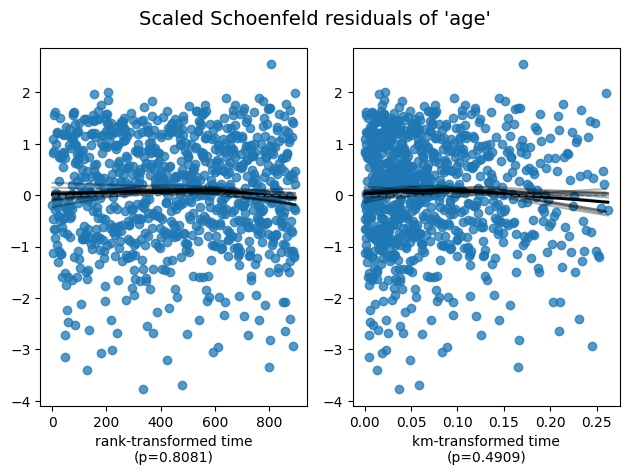

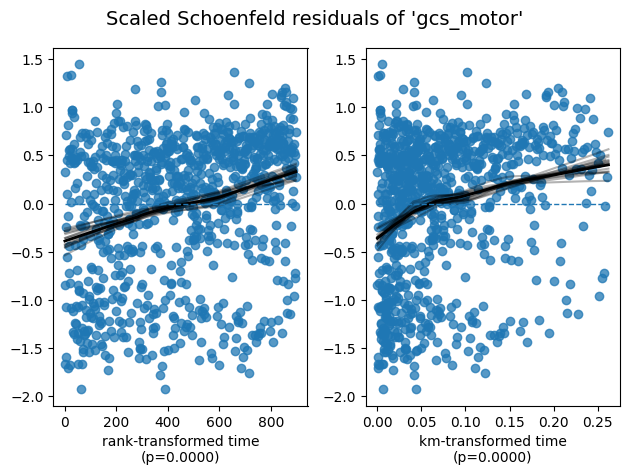

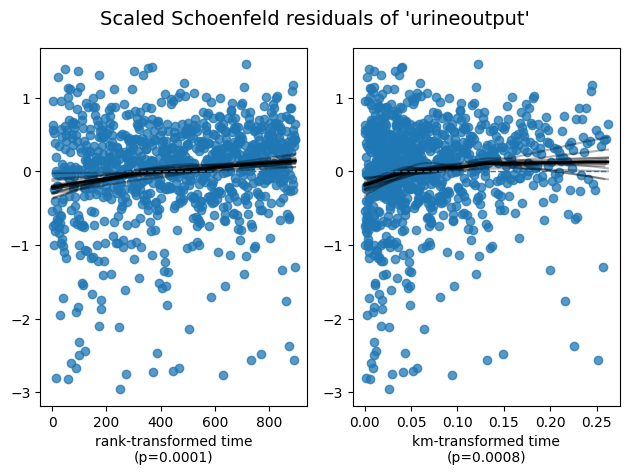

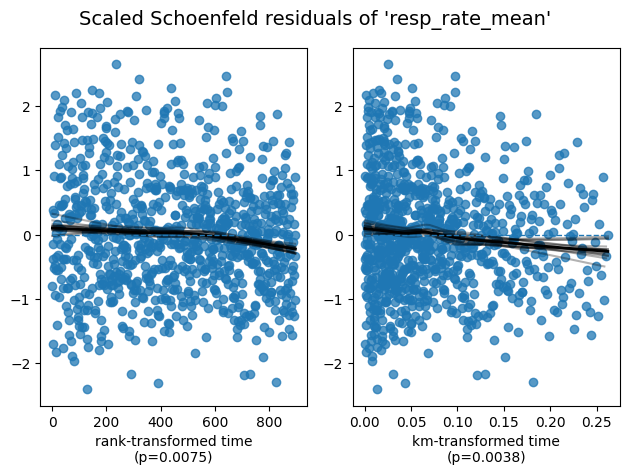

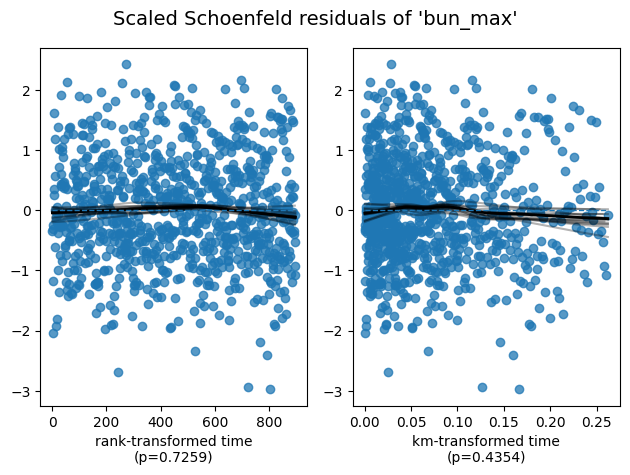

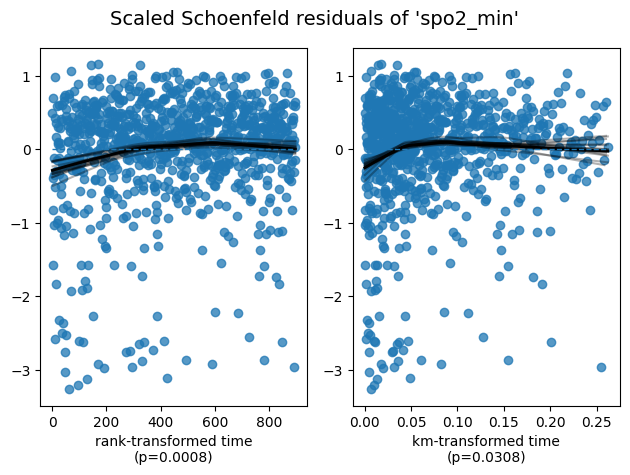

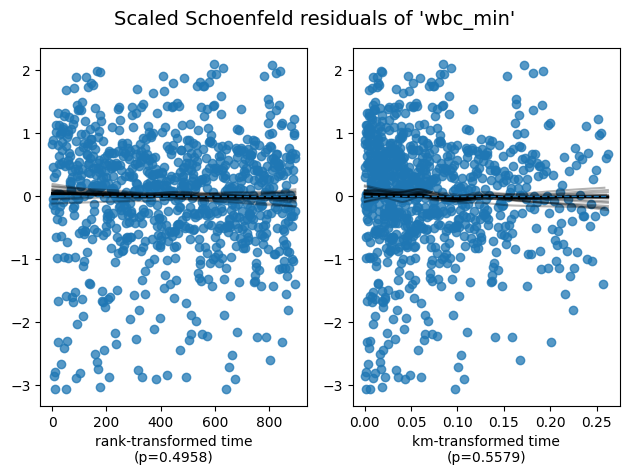

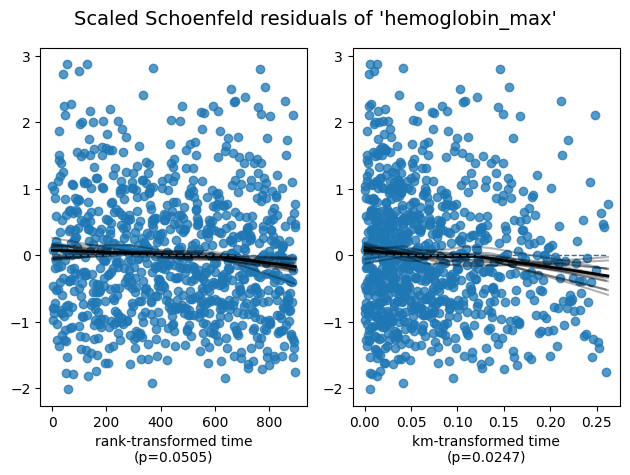

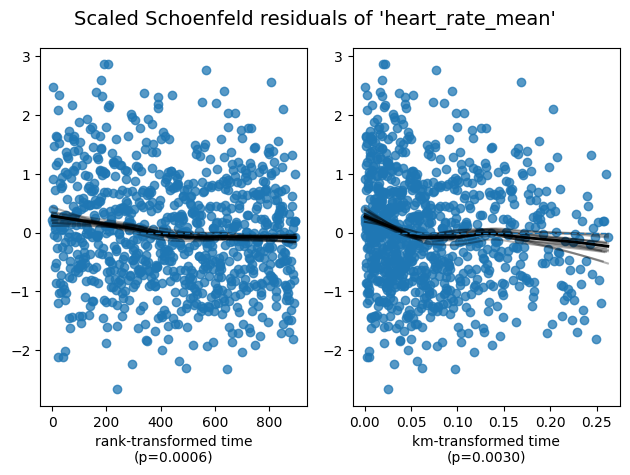

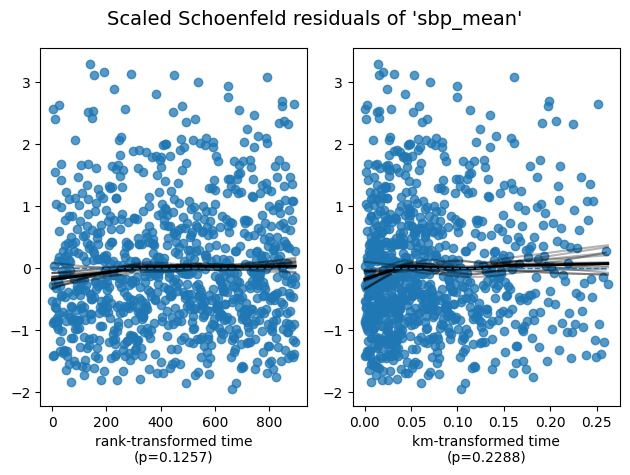

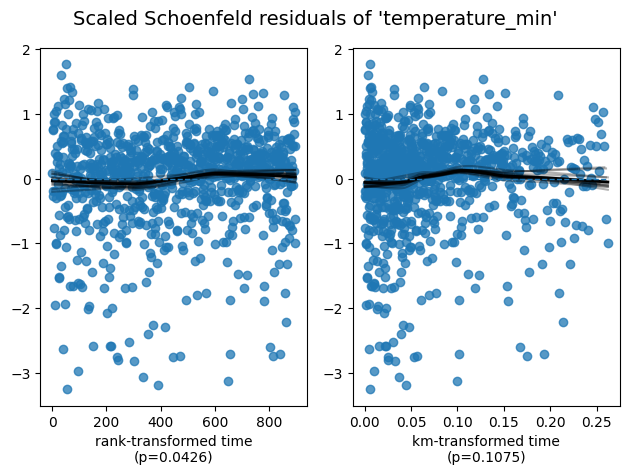

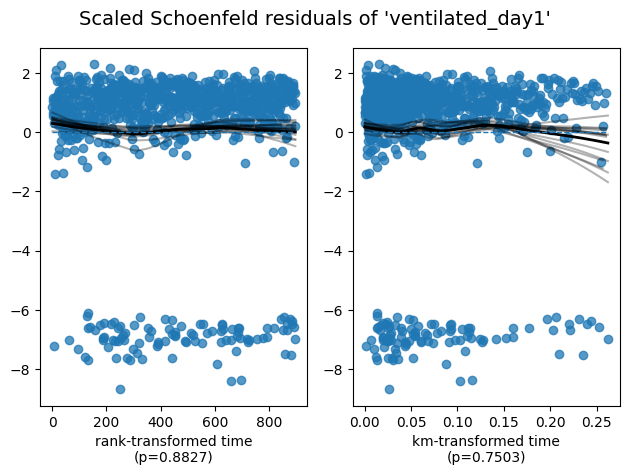

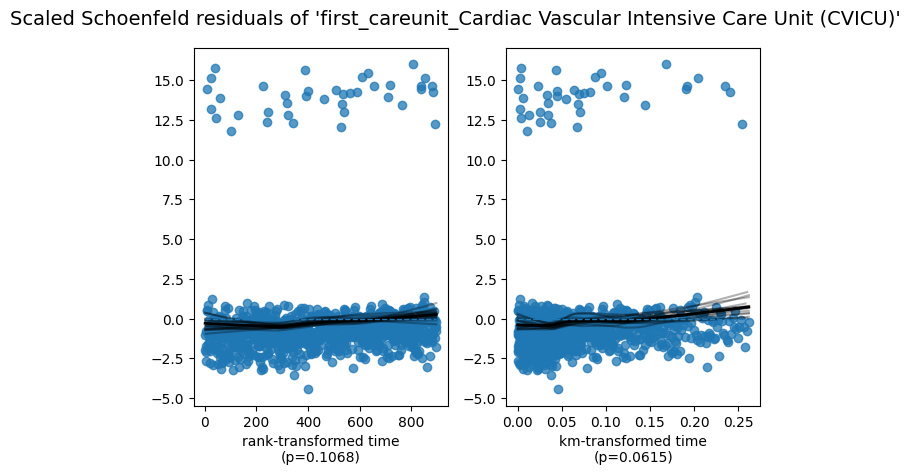

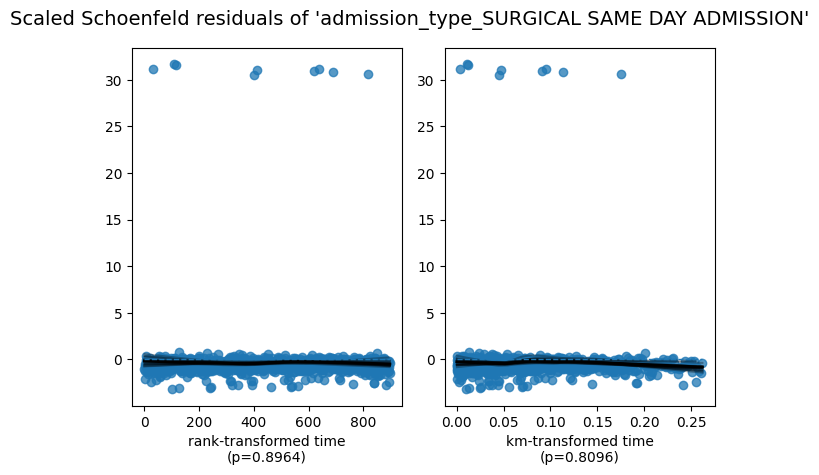

In [55]:
sample = (train_df.drop(columns='subject_id')
                  .sample(10000, random_state=0)
                  .reset_index(drop=True))
cph_s = CoxPHFitter(penalizer=0.01).fit(sample, 'duration_days', 'event')
cph_s.check_assumptions(sample, p_value_threshold=0.001, show_plots=True)
plt.savefig("cph_s.png", dpi=300, bbox_inches="tight")

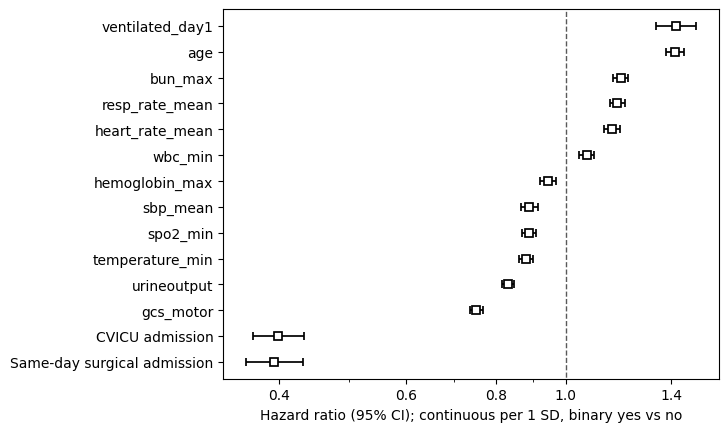

In [56]:
ax = cph.plot(hazard_ratios=True)
ax.set_xscale('log')
ax.set_xticks([0.4, 0.6, 0.8, 1.0, 1.4])
ax.set_xticklabels(['0.4', '0.6', '0.8', '1.0', '1.4'])
ax.set_xlabel('Hazard ratio (95% CI); continuous per 1 SD, binary yes vs no')
labels = [t.get_text()
          .replace('first_careunit_Cardiac Vascular Intensive Care Unit (CVICU)', 'CVICU admission')
          .replace('admission_type_SURGICAL SAME DAY ADMISSION', 'Same-day surgical admission')
          for t in ax.get_yticklabels()]
ax.set_yticklabels(labels)
ax.figure.savefig('cox_forest.png', dpi=300, bbox_inches='tight')